# Day 8 – Holt's Linear Trend Method

## Forecasting time series with level and trend

Holt's Linear Trend method (also called double exponential smoothing) extends Simple Exponential Smoothing (SES) by modelling **two components**:

- **Level**: the estimated current value of the series.
- **Trend**: the estimated direction and rate of change.

It is suitable for data with a trend but no strong seasonality. This notebook builds the method from scratch, compares smoothing parameters, evaluates forecasts using a chronological split, and uses `statsmodels` for a library implementation.

> The synthetic dataset is designed for learning. Real demand data should be checked for seasonality, structural changes, outliers, and intermittent demand before choosing this method.

### Learning objectives
1. Understand Holt's level and trend equations.
2. Implement one-step-ahead fitted values without data leakage.
3. Generate multi-step forecasts.
4. Understand the level and trend smoothing parameters.
5. Tune parameters on validation data and evaluate on a separate test set.
6. Compare Holt's method with SES and discuss its supply-chain applications.

## 1. Import libraries

We use NumPy and pandas for data handling, Matplotlib for visualization, scikit-learn metrics for evaluation, and Statsmodels for a second implementation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import Holt, SimpleExpSmoothing

np.random.seed(42)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

## 2. Create a synthetic time series with an upward trend

The data contains a starting demand level, a gradual upward trend, and random noise. We intentionally do not add seasonality because basic Holt's method does not model seasonal patterns.

In [2]:
n_periods = 96
dates = pd.date_range("2018-01-01", periods=n_periods, freq="MS")
time = np.arange(n_periods)

base_level = 120
true_trend = 1.25
noise = np.random.normal(loc=0, scale=7, size=n_periods)

demand = base_level + true_trend * time + noise
series = pd.Series(demand, index=dates, name="Demand")

series.head()

2018-01-01    123.476999
2018-02-01    120.282150
2018-03-01    127.033820
2018-04-01    134.411209
2018-05-01    123.360926
Freq: MS, Name: Demand, dtype: float64

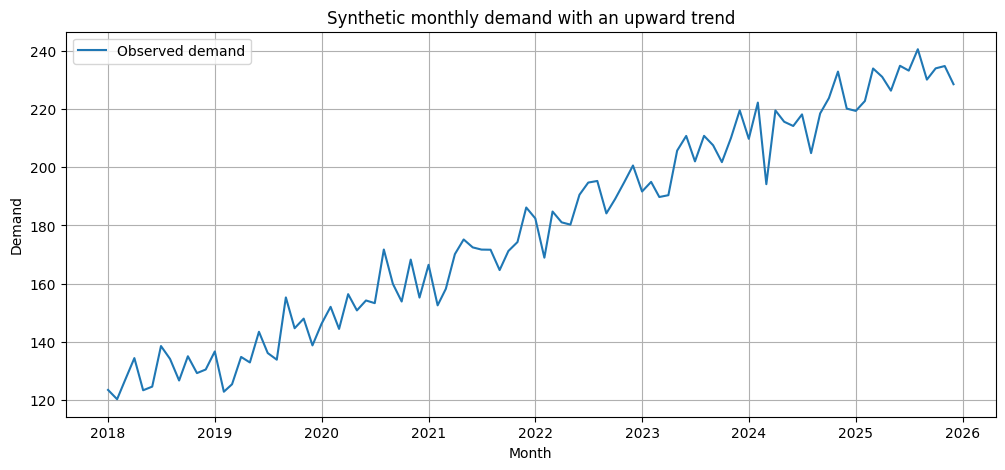

In [3]:
plt.figure()
plt.plot(series, label="Observed demand")
plt.title("Synthetic monthly demand with an upward trend")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.legend()
plt.show()

## 3. Holt's Linear Trend equations

Holt's method updates both the estimated level and the estimated trend at each time step.

**Level equation**

$$L_t = \alpha Y_t + (1-\alpha)(L_{t-1}+T_{t-1})$$

**Trend equation**

$$T_t = \beta(L_t-L_{t-1}) + (1-\beta)T_{t-1}$$

**Forecast equation**

$$\hat{Y}_{t+h|t} = L_t + hT_t$$

Where:

- $Y_t$: actual observation at time $t$
- $L_t$: estimated level at time $t$
- $T_t$: estimated trend at time $t$
- $\alpha$: level smoothing parameter, between 0 and 1
- $\beta$: trend smoothing parameter, between 0 and 1
- $h$: number of periods ahead

The level update combines the latest actual value with the previous period's projected level. The trend update smooths the change in level. Forecasts extend the latest level by the estimated trend.

### What do alpha and beta control?

- **Alpha (α)** controls how quickly the level responds to new observations.
- **Beta (β)** controls how quickly the estimated trend responds to changes in the level.

Higher values generally make the corresponding component more responsive; lower values produce smoother updates.

## 4. Work through a small numerical example

Assume:

- Initial level $L_0 = 100$
- Initial trend $T_0 = 5$
- Actual observations: 108, 111, 115
- $\alpha = 0.4$
- $\beta = 0.3$

For the first observation:

$$L_1 = 0.4(108) + 0.6(100+5) = 106.2$$

$$T_1 = 0.3(106.2-100) + 0.7(5) = 5.36$$

The one-step-ahead forecast for the next period is:

$$\hat{Y}_{2|1} = L_1 + T_1 = 111.56$$

The same update process repeats as each new actual observation becomes available.

In [4]:
def holt_manual(y, alpha=0.4, beta=0.3, initial_level=None, initial_trend=None):
    """Fit additive Holt's linear trend and return fitted values and final states.

    fitted[t] is the forecast made before observing y[t] (one-step-ahead).
    The first fitted value is NaN because no prior state is available.
    """
    y = np.asarray(y, dtype=float)
    if len(y) < 2:
        raise ValueError("At least two observations are required.")
    if not (0 <= alpha <= 1 and 0 <= beta <= 1):
        raise ValueError("alpha and beta must be between 0 and 1.")

    level = float(y[0] if initial_level is None else initial_level)
    trend = float(y[1] - y[0] if initial_trend is None else initial_trend)

    fitted = np.full(len(y), np.nan)
    levels = np.full(len(y), np.nan)
    trends = np.full(len(y), np.nan)
    levels[0], trends[0] = level, trend

    for t in range(1, len(y)):
        # Forecast for y[t], generated using information through t-1.
        fitted[t] = level + trend

        previous_level = level
        level = alpha * y[t] + (1 - alpha) * (level + trend)
        trend = beta * (level - previous_level) + (1 - beta) * trend

        levels[t] = level
        trends[t] = trend

    return {
        "fitted": fitted,
        "level": levels,
        "trend": trends,
        "final_level": level,
        "final_trend": trend,
    }

example_y = [100, 108, 111, 115]
example_fit = holt_manual(example_y, alpha=0.4, beta=0.3,
                          initial_level=100, initial_trend=5)

pd.DataFrame({
    "Actual": example_y,
    "One-step fitted": example_fit["fitted"],
    "Level": example_fit["level"],
    "Trend": example_fit["trend"],
})

,Actual,One-step fitted,Level,Trend
0,100,NaN,100.00000,5.000000
1,108,105.0000,106.20000,5.360000
2,111,111.5600,111.33600,5.292800
3,115,116.6288,115.97728,5.097344


## 5. Implement Holt's method from scratch

The function below stores the one-step-ahead forecast **before** updating the state with the current observation. This is important: using the current observation to forecast itself would cause data leakage and overly optimistic evaluation.

In [5]:
manual_result = holt_manual(series.values, alpha=0.35, beta=0.20)
manual_fitted = pd.Series(manual_result["fitted"], index=series.index)
level_component = pd.Series(manual_result["level"], index=series.index)
trend_component = pd.Series(manual_result["trend"], index=series.index)

display(pd.DataFrame({
    "Actual": series,
    "Fitted": manual_fitted,
    "Level": level_component,
    "Trend": trend_component
}).head(10))

,Actual,Fitted,Level,Trend
2018-01-01,123.476999,NaN,123.476999,-3.194849
2018-02-01,120.282150,120.282150,120.282150,-3.194849
2018-03-01,127.033820,117.087301,120.568582,-2.498593
2018-04-01,134.411209,118.069990,123.789416,-1.354707
2018-05-01,123.360926,122.434709,122.758885,-1.289872
2018-06-01,124.611041,121.469013,122.568723,-1.069930
2018-07-01,138.554490,121.498792,127.468287,0.123969
2018-08-01,134.122043,127.592255,129.877681,0.581054
2018-09-01,126.713679,130.458735,129.147965,0.318900
2018-10-01,135.047920,129.466865,131.420234,0.709574


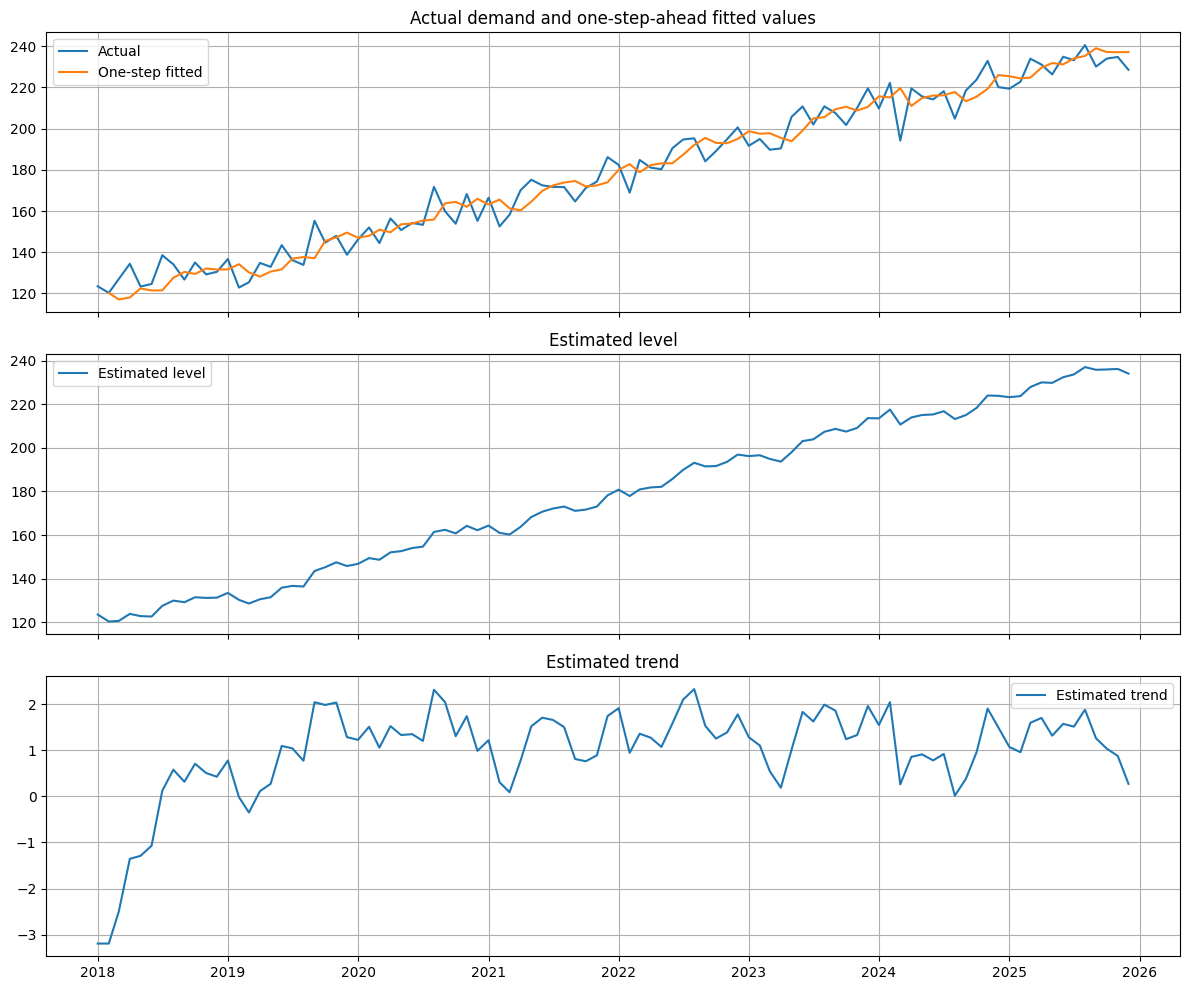

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axes[0].plot(series, label="Actual")
axes[0].plot(manual_fitted, label="One-step fitted")
axes[0].set_title("Actual demand and one-step-ahead fitted values")
axes[0].legend()

axes[1].plot(level_component, label="Estimated level")
axes[1].set_title("Estimated level")
axes[1].legend()

axes[2].plot(trend_component, label="Estimated trend")
axes[2].set_title("Estimated trend")
axes[2].legend()
plt.tight_layout()
plt.show()

## 6. Generate a multi-step forecast

For a forecast horizon of $h$ periods:

$$\hat{Y}_{T+h|T} = L_T + hT_T$$

The basic additive-trend version extends the latest estimated trend linearly. It does not automatically damp the trend, so long-horizon forecasts can become unrealistic if the trend cannot continue indefinitely.

In [7]:
def holt_forecast_from_state(final_level, final_trend, horizon, index=None):
    if horizon < 1:
        raise ValueError("horizon must be at least 1.")
    forecasts = [final_level + h * final_trend for h in range(1, horizon + 1)]
    if index is not None:
        return pd.Series(forecasts, index=index, name="Forecast")
    return np.asarray(forecasts)

future_dates = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1),
                             periods=12, freq="MS")
future_manual = holt_forecast_from_state(
    manual_result["final_level"],
    manual_result["final_trend"],
    horizon=12,
    index=future_dates
)
future_manual

2026-01-01    234.387688
2026-02-01    234.662190
2026-03-01    234.936692
2026-04-01    235.211193
2026-05-01    235.485695
2026-06-01    235.760196
2026-07-01    236.034698
2026-08-01    236.309200
2026-09-01    236.583701
2026-10-01    236.858203
2026-11-01    237.132705
2026-12-01    237.407206
Freq: MS, Name: Forecast, dtype: float64

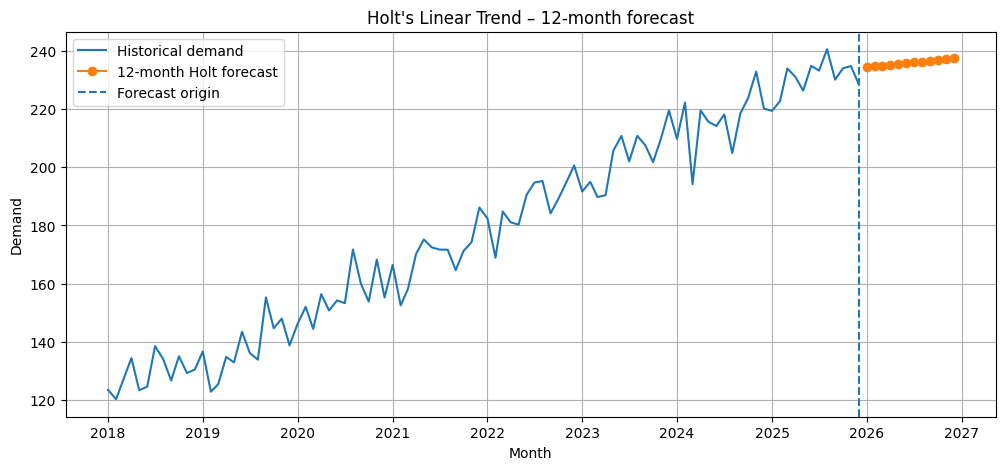

In [8]:
plt.figure()
plt.plot(series, label="Historical demand")
plt.plot(future_manual, marker="o", label="12-month Holt forecast")
plt.axvline(series.index[-1], linestyle="--", label="Forecast origin")
plt.title("Holt's Linear Trend – 12-month forecast")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.legend()
plt.show()

## 7. Understand the impact of alpha and beta

We compare several combinations. The purpose is to understand how level and trend responsiveness changes the fitted line; the best values should be selected using validation data rather than visual preference alone.

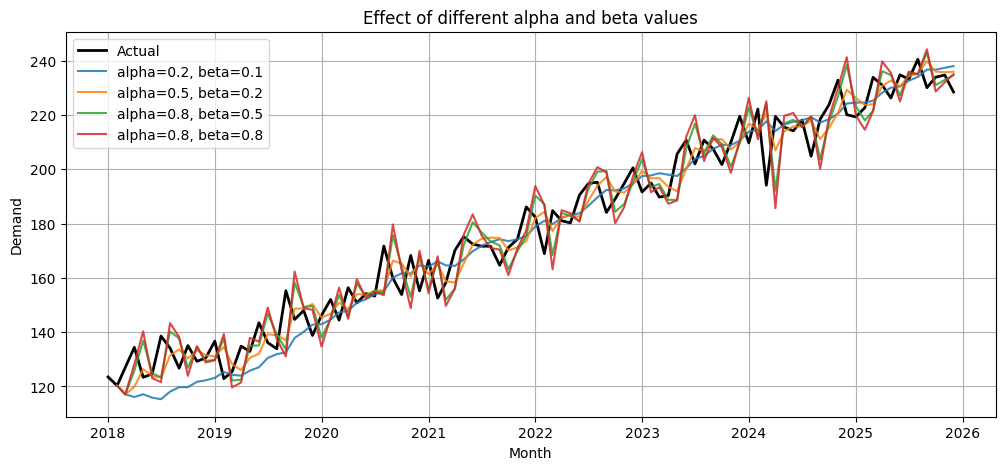

In [9]:
parameter_sets = [
    (0.2, 0.1),
    (0.5, 0.2),
    (0.8, 0.5),
    (0.8, 0.8),
]

plt.figure()
plt.plot(series, color="black", linewidth=2, label="Actual")
for alpha, beta in parameter_sets:
    result = holt_manual(series.values, alpha=alpha, beta=beta)
    fitted = pd.Series(result["fitted"], index=series.index)
    plt.plot(fitted, label=f"alpha={alpha}, beta={beta}", alpha=0.85)
plt.title("Effect of different alpha and beta values")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.legend()
plt.show()

## 8. Chronological train-validation-test split

For time series, do not randomly shuffle observations. We use:

- First 70%: training
- Next 15%: validation (for selecting alpha and beta)
- Final 15%: test (held out until final evaluation)

The test set is not used to choose parameters.

In [10]:
n = len(series)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train = series.iloc[:train_end]
validation = series.iloc[train_end:validation_end]
test = series.iloc[validation_end:]

print(f"Train:      {train.index.min().date()} to {train.index.max().date()} ({len(train)} points)")
print(f"Validation: {validation.index.min().date()} to {validation.index.max().date()} ({len(validation)} points)")
print(f"Test:       {test.index.min().date()} to {test.index.max().date()} ({len(test)} points)")

Train:      2018-01-01 to 2023-07-01 (67 points)
Validation: 2023-08-01 to 2024-09-01 (14 points)
Test:       2024-10-01 to 2025-12-01 (15 points)


## 9. Evaluate forecasts

We report MAE, RMSE, WMAPE, and mean error (bias).

- MAE: average absolute error.
- RMSE: penalizes larger errors more heavily.
- WMAPE: total absolute error divided by total actual demand.
- Mean error: average forecast minus actual; positive values indicate overforecasting.

MAPE is omitted here because WMAPE and scale-dependent metrics are more suitable for many demand-planning settings, especially when actuals may be zero.

In [11]:
def forecast_metrics(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    error = forecast - actual
    denominator = np.sum(np.abs(actual))
    wmape = np.sum(np.abs(error)) / denominator if denominator != 0 else np.nan
    return {
        "MAE": mean_absolute_error(actual, forecast),
        "RMSE": np.sqrt(mean_squared_error(actual, forecast)),
        "WMAPE": wmape,
        "Mean Error (Forecast - Actual)": np.mean(error),
    }

## 10. Tune alpha and beta on the validation window

For each candidate pair, fit the model on the training data and forecast the validation horizon. Select the pair with the lowest validation RMSE in this example. In practice, the selection metric should reflect the business objective and data characteristics.

In [12]:
candidate_alphas = [0.1, 0.2, 0.3, 0.5, 0.7, 0.9]
candidate_betas = [0.05, 0.1, 0.2, 0.4, 0.7, 0.9]

validation_results = []
for alpha in candidate_alphas:
    for beta in candidate_betas:
        result = holt_manual(train.values, alpha=alpha, beta=beta)
        val_forecast = holt_forecast_from_state(
            result["final_level"], result["final_trend"], len(validation)
        )
        metrics = forecast_metrics(validation.values, val_forecast)
        validation_results.append({
            "alpha": alpha, "beta": beta, **metrics
        })

validation_table = pd.DataFrame(validation_results).sort_values("RMSE")
display(validation_table.head(10))

best_row = validation_table.iloc[0]
best_alpha = float(best_row["alpha"])
best_beta = float(best_row["beta"])
print(f"Selected alpha={best_alpha}, beta={best_beta}")

,alpha,beta,MAE,RMSE,WMAPE,Mean Error (Forecast - Actual)
28,0.7,0.70,5.559437,7.401535,0.026238,-0.425767
30,0.9,0.05,5.715219,7.832743,0.026973,-0.264436
3,0.1,0.40,5.627095,7.874308,0.026557,0.548929
32,0.9,0.20,5.715447,7.948501,0.026974,0.479865
12,0.3,0.05,5.817219,8.055932,0.027454,1.101612
6,0.2,0.05,5.831584,8.056799,0.027522,0.770950
31,0.9,0.10,5.909171,8.109861,0.027888,0.946936
24,0.7,0.05,5.855695,8.135166,0.027636,1.737151
18,0.5,0.05,5.978785,8.265001,0.028217,2.108474
1,0.1,0.10,6.101370,8.352596,0.028795,2.168327


Selected alpha=0.7, beta=0.7


## 11. Refit on train + validation, then evaluate once on test

After selecting parameters, refit using all data available before the test window. Then forecast the test horizon and calculate final test metrics.

In [13]:
pre_test = series.iloc[:validation_end]
final_pretest_fit = holt_manual(pre_test.values,
                                alpha=best_alpha,
                                beta=best_beta)
test_forecast = holt_forecast_from_state(
    final_pretest_fit["final_level"],
    final_pretest_fit["final_trend"],
    horizon=len(test),
    index=test.index
)

display(pd.DataFrame({"Actual": test, "Forecast": test_forecast}))
print("Test metrics:")
print(pd.Series(forecast_metrics(test.values, test_forecast)))

,Actual,Forecast
2024-10-01,223.749788,215.889543
2024-11-01,232.845258,217.670720
2024-12-01,220.122108,219.451897
2025-01-01,219.340545,221.233074
2025-02-01,222.737701,223.014251
2025-03-01,233.907815,224.795428
2025-04-01,231.051258,226.576605
2025-05-01,226.291679,228.357783
2025-06-01,234.842872,230.138960
2025-07-01,233.179543,231.920137


Test metrics:
MAE                               5.308942
RMSE                              6.753261
WMAPE                             0.023110
Mean Error (Forecast - Actual)   -1.368998
dtype: float64


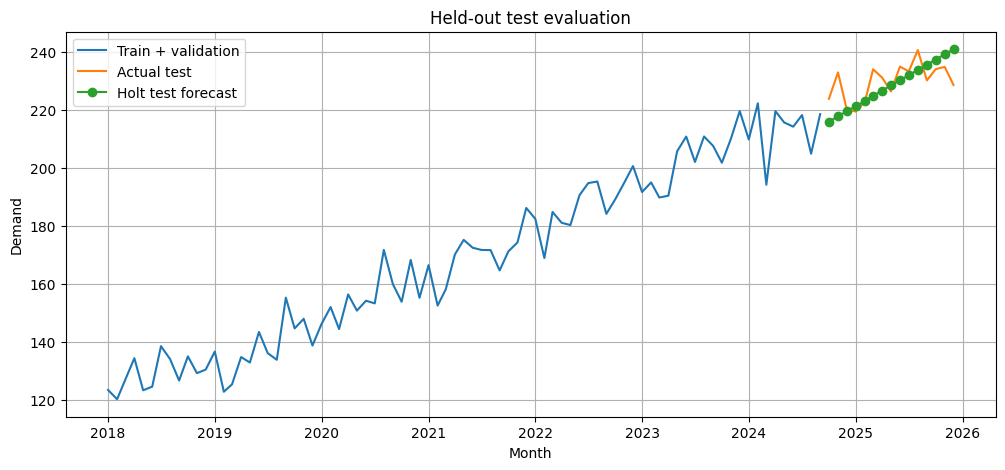

In [14]:
plt.figure()
plt.plot(pre_test, label="Train + validation")
plt.plot(test, label="Actual test")
plt.plot(test_forecast, marker="o", label="Holt test forecast")
plt.title("Held-out test evaluation")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.legend()
plt.show()

## 12. Compare Holt's method with Simple Exponential Smoothing

SES models level only and therefore produces a flat forecast. Holt's method models level and trend, so its forecast extends the estimated trend. On a series with a genuine trend, Holt may be more suitable; if there is no trend, SES may be sufficient.

In [15]:
ses_fit = SimpleExpSmoothing(train, initialization_method="estimated").fit(optimized=True)
ses_validation_forecast = ses_fit.forecast(len(validation))

holt_fit = Holt(train, initialization_method="estimated",
                damped_trend=False).fit(optimized=True)
holt_validation_forecast = holt_fit.forecast(len(validation))

comparison = pd.DataFrame([
    {"Model": "SES", **forecast_metrics(validation.values, ses_validation_forecast.values)},
    {"Model": "Holt's Linear Trend", **forecast_metrics(validation.values, holt_validation_forecast.values)}
])
display(comparison)

,Model,MAE,RMSE,WMAPE,Mean Error (Forecast - Actual)
0,SES,10.413359,11.814088,0.049146,-9.003289
1,Holt's Linear Trend,6.086355,8.040624,0.028725,-1.075011


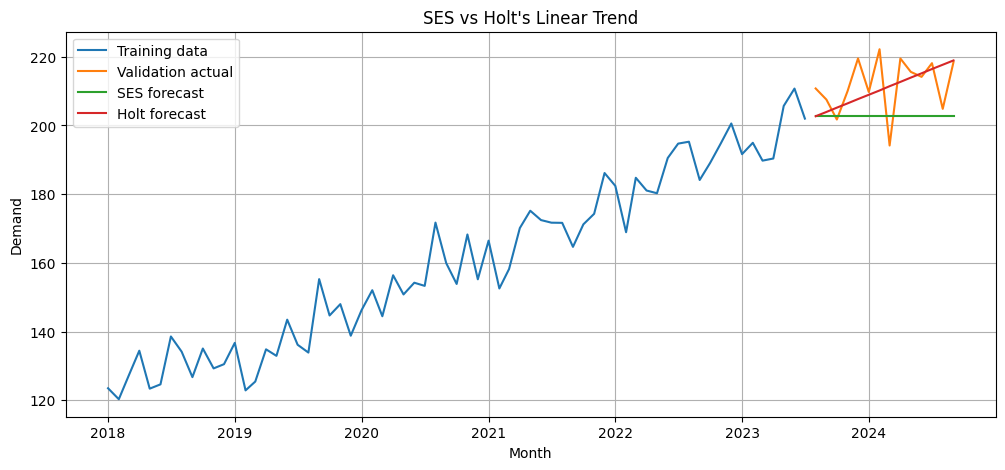

In [16]:
plt.figure()
plt.plot(train, label="Training data")
plt.plot(validation, label="Validation actual")
plt.plot(ses_validation_forecast, label="SES forecast")
plt.plot(holt_validation_forecast, label="Holt forecast")
plt.title("SES vs Holt's Linear Trend")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.legend()
plt.show()

## 13. Statsmodels implementation

Statsmodels provides Holt's method through `statsmodels.tsa.holtwinters.Holt`. The library estimates the initial states and can optimize smoothing parameters.

We demonstrate both an undamped and a damped trend. A damped trend gradually reduces the contribution of the trend over longer horizons, which can be more realistic when growth is not expected to continue indefinitely.

In [17]:
holt_model = Holt(train, initialization_method="estimated",
                   damped_trend=False)
holt_stats_fit = holt_model.fit(optimized=True)

print(holt_stats_fit.params)
stats_validation_forecast = holt_stats_fit.forecast(len(validation))
print(pd.Series(forecast_metrics(validation.values,
                                 stats_validation_forecast.values)))

{'smoothing_level': np.float64(1.4901161193847656e-08), 'smoothing_trend': np.float64(0.0), 'smoothing_seasonal': np.float64(nan), 'damping_trend': nan, 'initial_level': np.float64(117.69213688080765), 'initial_trend': np.float64(1.2499243021918593), 'initial_seasons': array([], dtype=float64), 'use_boxcox': False, 'lamda': None, 'remove_bias': False}
MAE                               6.086355
RMSE                              8.040624
WMAPE                             0.028725
Mean Error (Forecast - Actual)   -1.075011
dtype: float64


In [18]:
damped_model = Holt(train, damped_trend=True,
                     initialization_method="estimated")
damped_fit = damped_model.fit(optimized=True)
damped_validation_forecast = damped_fit.forecast(len(validation))

damped_comparison = pd.DataFrame([
    {"Model": "Holt – undamped", **forecast_metrics(validation.values, stats_validation_forecast.values)},
    {"Model": "Holt – damped", **forecast_metrics(validation.values, damped_validation_forecast.values)}
])
display(damped_comparison)

,Model,MAE,RMSE,WMAPE,Mean Error (Forecast - Actual)
0,Holt – undamped,6.086355,8.040624,0.028725,-1.075011
1,Holt – damped,5.819714,8.047418,0.027466,0.773769


## 14. Residual analysis

Residuals are actual values minus fitted values. Ideally, residuals should not show a systematic trend or obvious structure. A residual plot is a diagnostic, not proof that a model is appropriate.

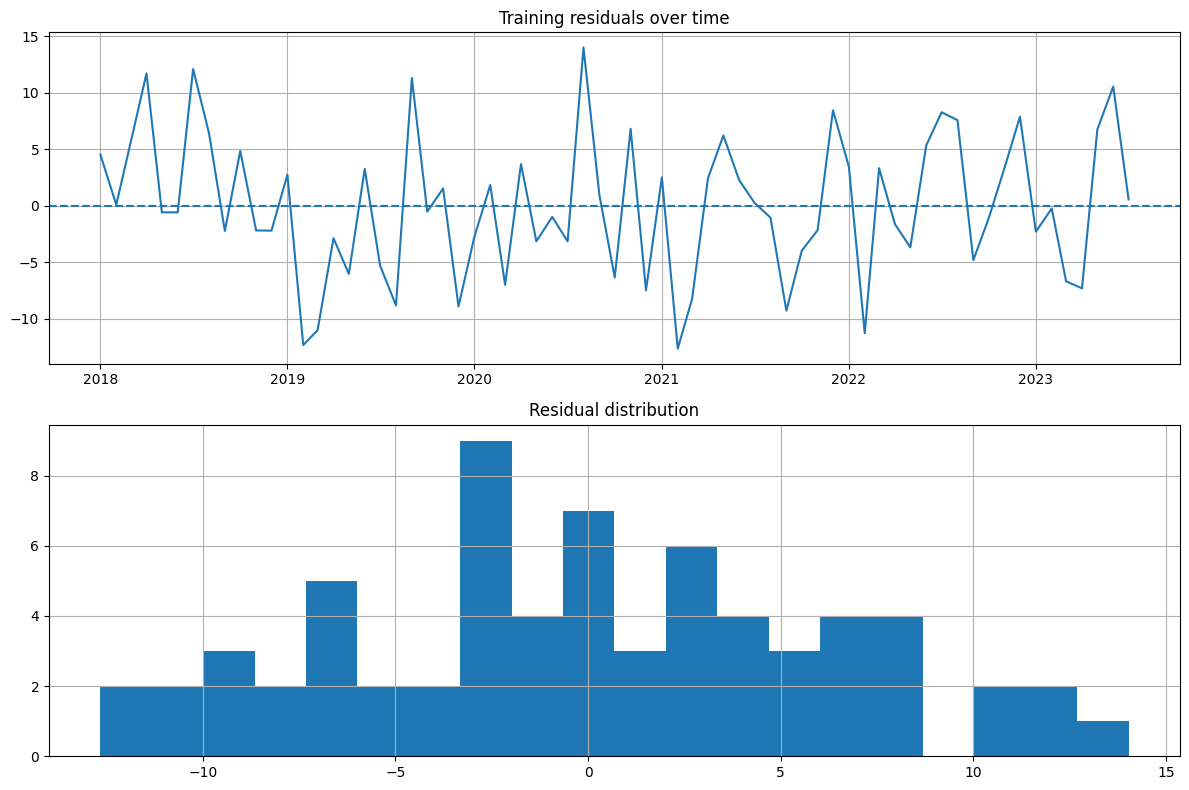

In [19]:
residuals = train - holt_stats_fit.fittedvalues

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].plot(residuals)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Training residuals over time")
axes[1].hist(residuals.dropna(), bins=20)
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.show()

## 15. Practical considerations for supply-chain forecasting

### When Holt's method may be useful
- Items with a reasonably stable upward or downward demand trend.
- Products with gradual growth or decline and no strong seasonal pattern.
- Baseline forecasts for item-location combinations with enough regular history.

### When to consider another method
- Strong seasonality: Holt-Winters or seasonal models.
- Intermittent demand with many zero periods: Croston-family methods or TSB.
- Abrupt promotions, price changes, launches, or disruptions: include relevant explanatory variables or use an event-aware approach.
- Trend that should not continue indefinitely: consider damped trend.

### Important modelling checks
1. Plot the series and inspect trend and seasonality.
2. Use time-ordered validation.
3. Select parameters using a metric aligned with the business objective.
4. Check bias as well as error magnitude.
5. Review residuals and forecast plausibility.
6. Evaluate across multiple item-location series, not only one synthetic example.

## 16. Advantages and limitations

### Advantages
- Models both level and trend.
- Relatively simple and computationally efficient.
- Can adapt to gradual changes in the trend.
- Does not require large datasets or many predictors.

### Limitations
- Basic Holt's method does not model seasonality.
- Linear trend extrapolation can become unrealistic at long horizons.
- Sudden structural changes may not be captured quickly.
- Results depend on smoothing parameters and initialization.
- It may be unsuitable for intermittent or highly erratic demand.

## 17. Summary: SES vs Holt vs Holt-Winters

| Method | Components modelled | Suitable pattern |
|---|---|---|
| Simple Exponential Smoothing | Level | No clear trend or seasonality |
| Holt's Linear Trend | Level + trend | Trend, no strong seasonality |
| Holt-Winters | Level + trend + seasonality | Trend and seasonality |

Holt's method is a natural next step after SES because it adds a separately smoothed trend component.

## 18. References

- Hyndman, R. J. and Athanasopoulos, G. *Forecasting: Principles and Practice* – Exponential smoothing.
- Statsmodels documentation – Holt's method and Holt-Winters exponential smoothing.

---

**Key takeaway:** SES estimates the level of a time series. Holt's Linear Trend extends SES by estimating both level and trend, allowing forecasts to follow a linear upward or downward trajectory when seasonality is not the dominant pattern.